In [2]:
import cv2 as cv
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from tensorflow import keras
from tensorflow.keras import layers

I0000 00:00:1793305265.463401  372999 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
path = "../../Z_Material/Datasets/cat_dog_1/"
files = os.listdir(path)
files[:5]

['train', 'test', '.DS_Store']

In [4]:
testdir = '../zz9_Material/Datasets/cat_dog_1/test/'
traindir = '../zz9_Material/Datasets/cat_dog_1/train/'
test = [os.path.join(testdir, f) for f in sorted(os.listdir(testdir)) if f.endswith(('.jpg', '.png'))]
train = [os.path.join(traindir, f) for f in sorted(os.listdir(traindir)) if f.endswith(('.jpg', '.png'))]

In [5]:
print(test[:5])
print(train[:5])

['../zz9_Material/Datasets/cat_dog_1/test/cat.3500.jpg', '../zz9_Material/Datasets/cat_dog_1/test/cat.3501.jpg', '../zz9_Material/Datasets/cat_dog_1/test/cat.3502.jpg', '../zz9_Material/Datasets/cat_dog_1/test/cat.3503.jpg', '../zz9_Material/Datasets/cat_dog_1/test/cat.3504.jpg']
['../zz9_Material/Datasets/cat_dog_1/train/cat.0.jpg', '../zz9_Material/Datasets/cat_dog_1/train/cat.1.jpg', '../zz9_Material/Datasets/cat_dog_1/train/cat.10.jpg', '../zz9_Material/Datasets/cat_dog_1/train/cat.100.jpg', '../zz9_Material/Datasets/cat_dog_1/train/cat.1000.jpg']


In [6]:
h,w = 128,128
images = []
classes = []

for img_path in train:
    img = cv.imread(img_path)
    if img is None:
        continue

    img = cv.resize(img, (w,h))
    img = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    #img = img.ravel()
    images.append(img)

    filename = os.path.basename(img_path)
    label = 0 if filename.startswith('cat') else 1
    classes.append(label)

print(images[0])
print(images[0].shape)

[[167 173 174 ... 210 207 204]
 [167 173 174 ... 211 207 205]
 [167 173 174 ... 212 208 206]
 ...
 [126 128 129 ...   3   3   2]
 [125 127 129 ...   3   3   3]
 [123 124 128 ...   2   2   2]]
(128, 128)


In [7]:
x = np.array(images)
x = x.astype("float32") / 255.0
y = np.array(classes)
print(x , '\n', y)


[[[0.654902   0.6784314  0.68235296 ... 0.8235294  0.8117647  0.8       ]
  [0.654902   0.6784314  0.68235296 ... 0.827451   0.8117647  0.8039216 ]
  [0.654902   0.6784314  0.68235296 ... 0.83137256 0.8156863  0.80784315]
  ...
  [0.49411765 0.5019608  0.5058824  ... 0.01176471 0.01176471 0.00784314]
  [0.49019608 0.49803922 0.5058824  ... 0.01176471 0.01176471 0.01176471]
  [0.48235294 0.4862745  0.5019608  ... 0.00784314 0.00784314 0.00784314]]

 [[0.16470589 0.17254902 0.17254902 ... 0.6431373  0.79607844 0.75686276]
  [0.16470589 0.16078432 0.15686275 ... 0.62352943 0.74509805 0.7607843 ]
  [0.15686275 0.14117648 0.13725491 ... 0.62352943 0.7176471  0.75686276]
  ...
  [0.08235294 0.07058824 0.07058824 ... 0.16862746 0.2901961  0.10980392]
  [0.10588235 0.08235294 0.08235294 ... 0.15294118 0.14509805 0.13333334]
  [0.11372549 0.07843138 0.07843138 ... 0.2        0.15686275 0.14509805]]

 [[0.13725491 0.0627451  0.1254902  ... 0.6        0.59607846 0.5803922 ]
  [0.17254902 0.172549

In [8]:
shape = x.shape
x = MinMaxScaler().fit_transform(x.reshape(len(x), -1)).reshape(shape)
x[0].max() , x[0].min()


(np.float32(0.9254902), np.float32(0.0))

In [9]:
print(x.shape)
print(y.shape)

(4000, 128, 128)
(4000,)


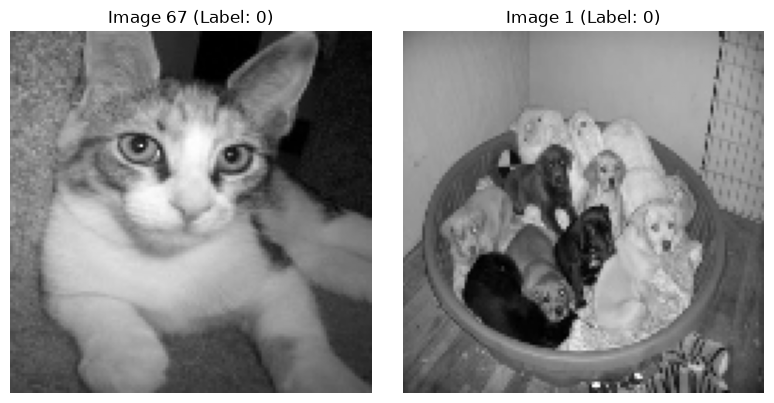

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(x[67].reshape(h, w), cmap='gray')
axes[0].set_title(f"Image 67 (Label: {y[0]})")
axes[0].axis('off')

axes[1].imshow(x[3888].reshape(h, w), cmap='gray')
axes[1].set_title(f"Image 1 (Label: {y[1]})")
axes[1].axis('off')

plt.tight_layout()
plt.show()

(array([0, 1]), array([2000, 2000]))


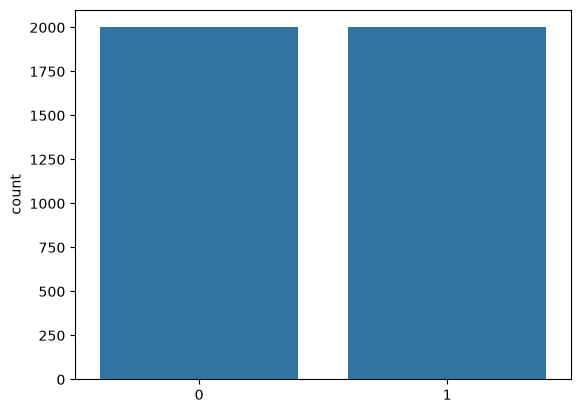

In [11]:
sns.countplot(x=y)
print(np.unique(y, return_counts=True))

In [12]:
x[0].max(), x[0].min()

(np.float32(0.9254902), np.float32(0.0))

In [13]:
print(x.shape, x.min(), x.max())   # expect (N, 128, 128, 1), ~0.0, ~1.0

(4000, 128, 128) 0.0 1.0


In [14]:
shape = x.shape
x = MinMaxScaler().fit_transform(x.reshape(len(x), -1)).reshape(shape)
x[0].max() , x[0].min()


(np.float32(0.9254902), np.float32(0.0))

In [15]:
x_train, x_test, y_train, y_test = train_test_split(x,y, random_state=42, test_size=0.2)
print(x_test.shape)
print(x_train.shape)
print(y_test.shape)
print(y_train.shape)

(800, 128, 128)
(3200, 128, 128)
(800,)
(3200,)


In [16]:
# hidden layers = (inputs +2) /2
(16384 + 2)/2

8193.0

In [17]:
network = keras.Sequential([
    layers.Input(shape=(128, 128, 1)),
    layers.Conv2D(16, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])
network.summary()

I0000 00:00:1793305270.393725  372999 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3062 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2060, pci bus id: 0000:01:00.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 16)   │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,521 (107.50 KB)

 Trainable params: 27,521 (107.50 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
network.compile(optimizer='Adam', loss = "binary_crossentropy", metrics=["accuracy"])
train_net = network.fit(x_train, y_train, epochs= 50, batch_size=32)

Epoch 1/50


I0000 00:00:1793305272.541736  373228 service.cc:153] XLA service 0x7f5f5c0bb810 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793305272.541757  373228 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2060, Compute Capability 7.5 (Driver: 13.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793305272.566659  373228 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793305272.840276  373228 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1793305272.850721  373228 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1943__.35


 14/100 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.5089 - loss: 0.6923

I0000 00:00:1793305278.486337  373228 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


100/100 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.5250 - loss: 0.6889
Epoch 2/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.5644 - loss: 0.6759
Epoch 3/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.5888 - loss: 0.6661
Epoch 4/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.6062 - loss: 0.6617
Epoch 5/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.6019 - loss: 0.6562
Epoch 6/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.6259 - loss: 0.6488
Epoch 7/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.6228 - loss: 0.6504
Epoch 8/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.6459 - loss: 0.6345
Epoch 9/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.6475 - loss: 0.6326
Epoch 10/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.6631 - loss: 0.6192
Epoch 11/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.6656 - loss: 0.6138
Epoch 12/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/ste

In [19]:
print(train_net.history.keys())

dict_keys(['accuracy', 'loss'])


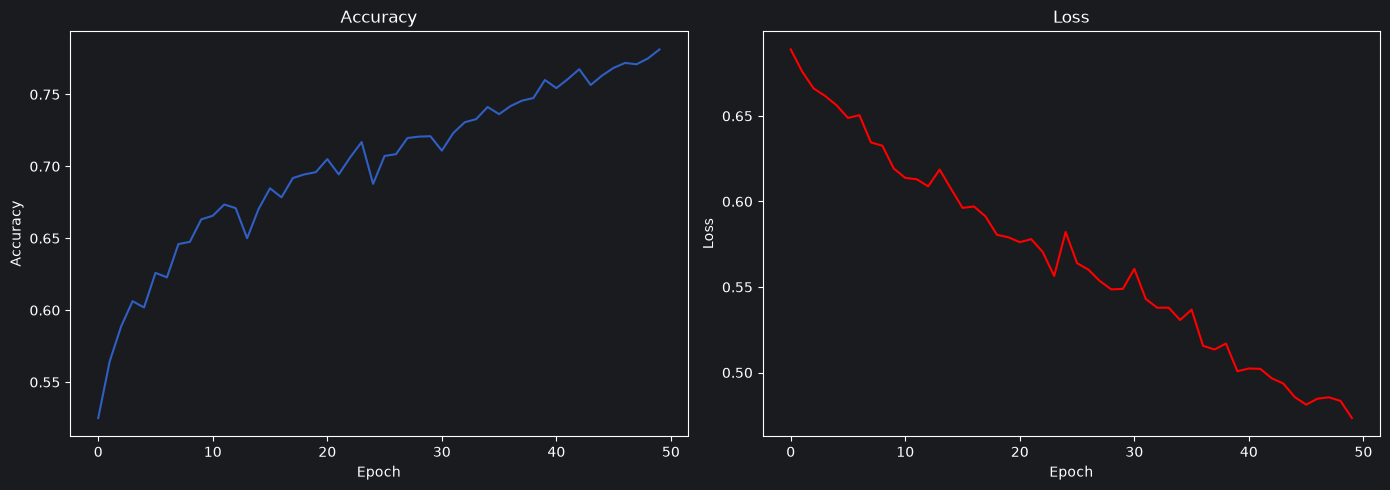

In [20]:

plt.style.use("dark_background")   # dark bg, light text and axes

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.set_facecolor("#1a1b1e")

for a in axes:
    a.set_facecolor("#1a1b1e")

axes[0].plot(train_net.history["accuracy"], color="#2f5fc4")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")

axes[1].plot(train_net.history["loss"], color="red")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")

plt.tight_layout()
plt.show()

/home/suupatruupa/Documents/hmph/4_ML-CV/1_Computer_Vision/.venv/lib/python3.12/site-packages/visualkeras/layered.py:231: UserWarning: The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.
  warnings.warn("The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.")


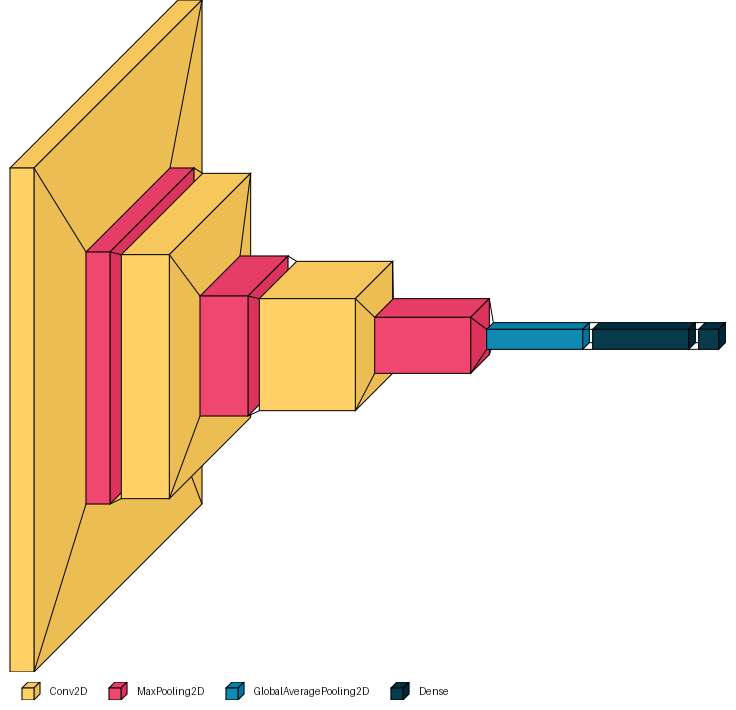

In [22]:
for l in network.layers:
    l.output_shape = tuple(l.output.shape)

import visualkeras
visualkeras.layered_view(network, legend=True)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step


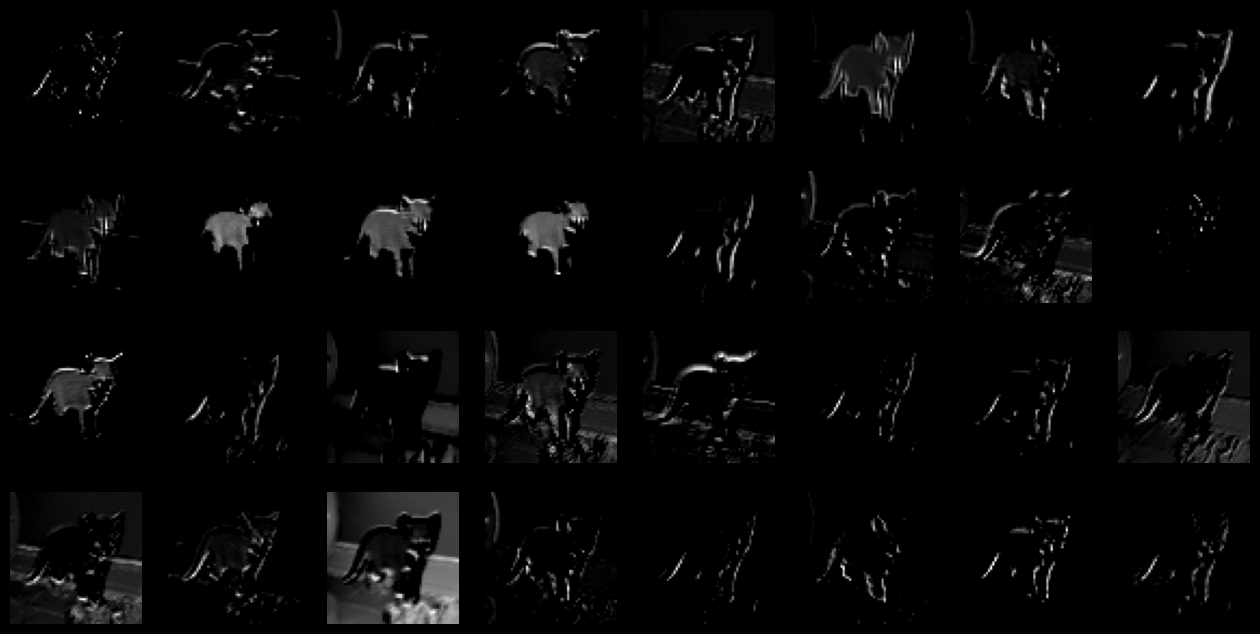

In [37]:
feat_model = keras.Model(network.inputs, network.layers[2].output)   # 2nd Conv2D
i=1
maps = feat_model.predict(x_test[i-1:i])
fig, axes = plt.subplots(4, 8, figsize=(16, 8))
for i, a in enumerate(axes.flat):
    a.imshow(maps[0, :, :, i], cmap="gray"); a.axis("off")
plt.show()